# TRUST 2026 Submission | November 2026 

## Agreeing or Fitting? Auditing LLM Judges Across Hate Speech Dimensions Beyond Conventional Agreement Metrics

In [3]:
%load_ext autoreload
%autoreload 0

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import cohen_kappa_score
import krippendorff
import importlib

# from scipy.stats import stats

import config, mfrm_analysis
importlib.reload(config)
importlib.reload(mfrm_analysis)

from config import DATA_DIR, DATA_DIR_MFRM, DIMENSIONS, Figures, OUTPUT_modu_5runs, COLORS, LLM_NAMES, ANNOTATOR_ID_MAP, OUTPUT_modu_only, DATA_modu_only, DATA_modu_mfrm
from mfrm_analysis import read_filepaths

all_filepaths = read_filepaths(base_dir=DATA_DIR) #take from the data directory not the mfrm rresults since we need the vote distribution
item_fit_stats = pd.read_csv(Path(OUTPUT_modu_only) / "item_diff_stats_all_modu_noHS.csv").rename(columns={'Unnamed: 0': 'Dimension'}) #joint MFRM calib
human_gold = pd.read_csv(Path(all_filepaths['gold'])).drop(columns="hatespeech")
claude_modu = pd.read_csv(Path(all_filepaths['claude_modu']))

DIMENSIONS = DIMENSIONS[:-1] #remove hatespeech dimension since we don't have it in the gold data

claude_modu

Config imported successfully!
Config imported successfully!


,text,comment_id,annotator_id,sentiment,respect,insult,humiliate,status,dehumanize,violence,genocide,attack_defend,hatespeech,vote_distributions,rater_method,rater_type
0,"Dwight Howard is a undercover Faggot, this guy...",43341,claude-haiku-4-5-20251001_modu,4,4.0,4.0,4.0,4.0,1.0,1.0,0.0,4.0,2,"{""sentiment"": {""4"": 5}, ""respect"": {""4"": 5}, ""...",LLM_majority,LLM
1,All India Mahila Congress has termed the Trans...,27447,claude-haiku-4-5-20251001_modu,3,2.0,1.0,1.0,3.0,0.0,0.0,0.0,1.0,0,"{""sentiment"": {""4"": 2, ""3"": 3}, ""respect"": {""2...",LLM_majority,LLM
2,Black Americans are standing up for President ...,31223,claude-haiku-4-5-20251001_modu,1,2.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0,"{""sentiment"": {""1"": 5}, ""respect"": {""1"": 1, ""2...",LLM_majority,LLM
3,@Vamsi Krishna so now a transgender can give b...,43580,claude-haiku-4-5-20251001_modu,4,4.0,4.0,4.0,4.0,2.0,0.0,0.0,4.0,2,"{""sentiment"": {""4"": 5}, ""respect"": {""4"": 4, ""3...",LLM_majority,LLM
4,This is what happens when you give blacks tota...,48916,claude-haiku-4-5-20251001_modu,4,4.0,4.0,4.0,4.0,2.0,1.0,0.0,4.0,2,"{""sentiment"": {""4"": 5}, ""respect"": {""4"": 5}, ""...",LLM_majority,LLM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,@yummyleika bitch same especially one dumb bitch,32646,claude-haiku-4-5-20251001_modu,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,"{""sentiment"": {""4"": 3, ""3"": 2}, ""respect"": {},...",LLM_majority,LLM
246,ISIS commander: ▪️I killed and slaughtered abo...,38712,claude-haiku-4-5-20251001_modu,4,4.0,4.0,4.0,4.0,0.0,1.0,1.0,4.0,0,"{""sentiment"": {""4"": 5}, ""respect"": {""4"": 4, ""0...",LLM_majority,LLM
247,Your favorite rapist pastor is showing his cul...,31852,claude-haiku-4-5-20251001_modu,4,4.0,4.0,4.0,4.0,4.0,2.0,0.0,4.0,1,"{""sentiment"": {""4"": 5}, ""respect"": {""4"": 5}, ""...",LLM_majority,LLM
248,"Yeah prolly not. Still got cordae, coldest rap...",33332,claude-haiku-4-5-20251001_modu,4,4.0,4.0,4.0,4.0,1.0,0.0,0.0,4.0,0,"{""sentiment"": {""4"": 5}, ""respect"": {""4"": 5}, ""...",LLM_majority,LLM


In [7]:
item_fit_stats

,Dimension,Estimate,SE,Count,Facility,Infit MS,Outfit MS
0,sentiment,-1.747,0.085,1605,0.761,1.576,1.326
1,respect,-1.672,0.100,1526,0.721,1.530,1.425
2,insult,-0.657,0.084,1526,0.635,1.654,1.580
3,humiliate,-0.062,0.071,1525,0.593,1.842,2.002
4,status,-0.636,0.098,1519,0.704,1.652,3.771
5,dehumanize,0.951,0.089,1526,0.364,2.387,2.635
6,violence,1.859,0.158,1526,0.165,2.605,2.408
7,genocide,2.813,0.212,1526,0.063,2.500,2.098
8,attack_defend,-0.849,0.078,1526,0.684,1.505,2.175


# Part 1: Consistency 
For sonsistency we will use the content of the DATA_DIR since it comatains the raw vote dictribution

In [3]:
def parse_vote_distributions(df):
    '''In this section we expand all the llm ratings formthe vote_distribution'''
    records = []

    for _, row in df.iterrows():
        try:
            vote_dist = json.loads(row['vote_distributions'])
        except (TypeError, ValueError):
            vote_dist = {}

        record = {
            'comment_id':   row['comment_id'],
            'annotator_id': row['annotator_id'],
        }

        for dim in DIMENSIONS: 
            counts = vote_dist.get(dim) or {}
            ratings = [int(k) for k, c in counts.items() for _ in range(int(c))]
            n = len(ratings)
            record[f'{dim}_5rating'] = ratings
            record[f'{dim}_n_runs'] = n

            if n == 0:
                for suffix in ('sd', 'spread', 'entropy', 'n_nonzero'):
                    record[f'{dim}_{suffix}'] = np.nan
                continue

            arr = np.array(ratings)
            # Self-consistency metric

            record[f'{dim}_sd'] = round(float(np.std(arr, ddof=1)), 3) if n > 1 else np.nan #bessels since using sanple
            record[f'{dim}_spread'] = int(arr.max() - arr.min())
            record[f'{dim}_n_nonzero'] = int((arr > 0).sum())#cout number of non-zero ratings

            probs = np.array([int(c) for c in counts.values()], dtype=float)
            probs = probs[probs > 0]
            probs /= probs.sum()
            record[f'{dim}_entropy'] = round(max(0.0, float(-(probs * np.log2(probs)).sum())), 3)

        records.append(record)
    return pd.DataFrame(records)

def self_consistency_analysis(file_map, expected_runs=5):
    all_results= []
    for filename, file_path in file_map.items():
        if filename not in non_modu_models:
            dataset = pd.read_csv(Path(file_path))
            consistency_df = parse_vote_distributions(dataset)
            consistency_df['model'] = filename
            # sanity check: how many comment-dimension cells do NOT have the expected run count
            bad = sum((consistency_df[f'{d}_n_runs'] != expected_runs).sum() for d in DIMENSIONS)
            print(f"{filename}: {len(consistency_df)} comments, {bad} cells with != {expected_runs} runs")
            all_results.append(consistency_df)
    combined = pd.concat(all_results,ignore_index=True)
    return combined

def summarize_consistency_per_model(combined_df):
    summary_rows = []
    for model, g in combined_df.groupby('model'):
        row = {'model': model}
        for dim in DIMENSIONS:  
            sd_col , spr_col, non_zero = g[f'{dim}_sd'], g[f'{dim}_spread'], g[f'{dim}_n_nonzero']
            valid = sd_col.notna()
            if not valid.any():
                continue
            row[f'{dim}_mean_sd'] = round(sd_col.mean(), 3)
            row[f'{dim}_pct_any_disagreement'] = round((sd_col[valid] > 0).mean() * 100, 1)
            row[f'{dim}_all_zero_pct'] = round((non_zero[valid] == 0).mean() * 100, 1)
            row[f'{dim}_mean_spread'] = round(spr_col.mean(), 3)
            row[f'{dim}_high_spread_pct'] = round((spr_col[valid] >= 2).mean() * 100, 1)
        summary_rows.append(row)
    return pd.DataFrame(summary_rows)


def find_high_variance_comments(combined_df, threshold=2):
    """
    Flag comments where spread >= threshold on any dimension.
    """
    combined_df = combined_df.copy()
    pairs = [(d, f'{d}_spread') for d in DIMENSIONS if f'{d}_spread' in combined_df.columns]

    spread_cols = [col for _, col in pairs]

    combined_df['max_spread'] = combined_df[spread_cols ].max(axis=1)
    combined_df['high_spread'] = combined_df['max_spread'] >= threshold
    combined_df['flagged_dims'] = combined_df[spread_cols].apply(
        lambda row: [d for d, c in pairs if row[c] >= threshold], axis=1)
    return combined_df

# Part 2: Putting all the human pooled fit dimensions together for eacy merging

In [2]:
anchored_col= {
    'claude_modu'   : 'item_stats_human_claude_modu_only.csv',
    'gemini_modu'   : 'item_stats_human_gemini_modu_only.csv',
    'gpt-5-mini_modu' : 'item_stats_human_gpt5mini_modu_only.csv',
    'deepseek_modu' : 'item_stats_human_deepseek_modu_only.csv',
}
anchored_df = []
for llm, fname in anchored_col.items():
    t = pd.read_csv(Path((OUTPUT_modu_only)/fname), index_col=0)
    t = t.reset_index().rename(columns={'index': 'Dimension',
                                        'Infit MS': 'Infit_anch',
                                        'Outfit MS': 'Outfit_anch'})
    t['LLM'] = llm
    anchored_df.append(t[['LLM', 'Dimension', 'Infit_anch', 'Outfit_anch']])

anchored_long_df = pd.concat(anchored_df, ignore_index=True)
# anchored_long_df.to_csv(Path(OUTPUT_modu_only)/'pooled_stats_modu_noHS.csv', index=False)

# Part 3: Computing Agreemnt metrics 

In this section, the idea is to compute the agreeemnt metric between the human amjority and the LLM 5 run majority. All majorities are computed as a mode with median tie breaker. 

In [4]:
from itertools import combinations
LABELS = [0, 1, 2, 3, 4]

def qwk_w(a, b, w=None):
    if len(set(a)) == 1 and len(set(b)) == 1:
        return np.nan
    return cohen_kappa_score(a, b, weights='quadratic', labels=LABELS, sample_weight=w)

def mae_w(a, b, w=None):  return np.average(np.abs(a - b), weights=w)

def bias_w(a, b, w=None): return np.average(a - b, weights=w)

def _idx(human_llm):
    return pd.Series(np.arange(len(human_llm['cid']))).groupby(human_llm['cid']).indices

def boot_ci_rows(stat_fn, human_llm, hh=None, n_boot=1000, seed=0):
    """Cluster bootstrap over comments. With hh: CI for stat(human_llm) - stat(hh), same resample."""
    rng = np.random.default_rng(seed)
    comments = np.unique(human_llm['cid'])
    ia = _idx(human_llm); ih = _idx(hh) if hh is not None else None #find the indices of each comment in the human_llm and hh data
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(comments, len(comments)) #randomly sample comments with replacement
        sa = np.concatenate([ia[c] for c in pick])
        v = stat_fn(human_llm['a'][sa], human_llm['b'][sa], human_llm['weights'][sa])
        if hh is not None:
            sh = np.concatenate([ih[c] for c in pick])
            v = v - stat_fn(hh['a'][sh], hh['b'][sh], hh['weights'][sh])
        if not np.isnan(v): vals.append(v)
    return tuple(np.percentile(vals, [2.5, 97.5]).round(3)) if len(vals) > 100 else (np.nan, np.nan)

def alpha_matrix(m):
    #annotators by comments
    try: return krippendorff.alpha(reliability_data=m.astype(float), value_domain=LABELS, level_of_measurement='ordinal')
    except Exception as e:
        print("alpha failed:", repr(e))
        return np.nan

def boot_ci_cols(matrix, n_boot=1000, seed=0):
    #creat a random number generator
    rng = np.random.default_rng(seed)
    #number of comments
    n = matrix.shape[1]
    vals=[]
    for _ in range(n_boot):
        sampled_cols = rng.integers(0, n, n) #low, high, size
        sampled_matrix = matrix[:, sampled_cols]
        krip_alpha = alpha_matrix(sampled_matrix)
        if not np.isnan(krip_alpha):
            vals.append(krip_alpha)
    return tuple(np.percentile(vals, [2.5, 97.5]).round(3)) if len(vals) > 100 else (np.nan, np.nan)


def compute_run_kripp(summary_df, dimensions=DIMENSIONS):
    rows = []
    for model, g in summary_df.groupby('model'):
        for d in dimensions:
            lists = g[f'{d}_5rating']
            ok = lists.apply(lambda x: isinstance(x, (list, np.ndarray)) and len(x) == 5)
            if not ok.any(): continue
            m = np.vstack(lists[ok].values).T          # 5 runs x comments
            rows.append({'Model': model, 'Dimension': d,
                         'Kripp_alpha_runs': round(alpha_matrix(m), 4),
                         'CI': boot_ci_cols(m), 
                         'n_comments': m.shape[1]})
    return pd.DataFrame(rows)


def compute_human_kripp_baseline(
        human_df,
        labels=range(5),
        dimensions=DIMENSIONS):
    """
    Compute Krippendorff alpha among human raters who rated the same comment.
    Only comments with at least 2 human raters are included.
    """
    results = []

    for dim in dimensions:
        # Pivot: rows=comments, cols=annotators
        # Only comments with 2+ annotators
        matrix = human_df.pivot(
            index='comment_id',
            columns='annotator_id',
            values=dim
        )

        # Keep only comments with at least 2 non-null ratings
        valid_mask = matrix.notna().sum(axis=1) >= 2
        matrix_filtered = matrix[valid_mask]
        matrix_filtered = matrix_filtered.loc[:, matrix_filtered.notna().any(axis=0)]         # drop annotators with no remaining data
        n_comments = len(matrix_filtered)
        n_raters = matrix_filtered.shape[1]

        if n_comments < 2:
            print(f"{dim}: insufficient data")
            continue
        #compute Krippendorff's alpha and its confidence interval
        kappa_matrix = matrix_filtered.values.T
        alpha = alpha_matrix(kappa_matrix)
        varies = (matrix_filtered.nunique(axis=1) > 1).sum() #
        CI = boot_ci_cols(kappa_matrix)

        results.append({
            'Dimension':  dim,
            'Kripp_alpha_human': round(alpha, 4),
            'n_comments': matrix_filtered.shape[0],
            'CI': CI,
            'n_raters_kripp':   matrix_filtered.shape[1],
            'n_comments_with_disagreement': int(varies)
        })

        print(f"{dim:15s}: "
              f"α = {alpha:.4f}: CI = {CI}, "
              f"(n_comments={n_comments}, "
              f"n_raters={n_raters})")

    return pd.DataFrame(results)

"""
A comment with k human ratings contributes k rows to the LLM-human comparison (one LLM for each human rating),
but k(k-1)/2 pairs to the human-human baseline (one pair for each combination of human ratings). Meaning a 
comment with 5 raters gives 5 LLM rows but 10 human pairs. So the human baseline overweights heavily-rated comments, 
and the LLM side doesn’t. 

The two numbers still reflect different comment mixes, which breaks the like-with-like comparison. 
So we make all comments equal weights
"""

def human_human_pairs(human_df, dimension, comments):
    a, b, cid, weights = [], [], [], []
    sub = human_df[human_df.comment_id.isin(comments)][['comment_id', dimension]].dropna()
    for c, g in sub.groupby('comment_id'):
        v = g[dimension].astype(int).values
        k = len(v)
        if k < 2: continue
        for i, j in combinations(range(k), 2):
            a += [v[i], v[j]]; b += [v[j], v[i]];   # see the double counting of pairs, we add both (i,j) and (j,i) to the list
            cid += [c, c]
            weights += [1.0 / (k * (k - 1))] * 2 #that why we divide by k(k-1) to make the weight for each pair equal to 1/k(k-1)
    return dict(a=np.array(a), b=np.array(b), cid=np.array(cid), weights=np.array(weights))

def llm_human_pairs(llm_df, human_df, dimension, comments):
    assert llm_df['comment_id'].is_unique, "LLM file must be one row per comment"
    m = (human_df[['comment_id', 'annotator_id', dimension]].rename(columns={dimension: 'hu'}).merge(
        llm_df[['comment_id', dimension]].rename(columns={dimension: 'llm'}), on='comment_id').dropna())
    m = m[m.comment_id.isin(comments)].copy()
    k = m.groupby('comment_id')['comment_id'].transform('size') #size:number of human ratings for each comment addedd as a new column

    return dict(a = m['llm'].astype(int).values,
                b = m['hu'].astype(int).values, 
                cid = m['comment_id'].values,
                weights = (1.0 / k).values,
                rater=m['annotator_id'].values)


def merge_llm_human(human_df, all_filepaths, item_fit_stats, all_anchored_df, valid_rater=2): ### ablation with valid =1, was valid =2
    """Each LLM single run vs individual human ratings, benchmarked against human-human pairs
    on the same comments; every comment has equal total weight on both sides.
    Bias/gap = LLM - human; positive MAE_gap = LLM worse, positive QWK_gap = LLM better."""
    overall_df, all_metrics_corr = {}, []
  
    for llm_name, filepath in all_filepaths.items(): #for the llm data
        if llm_name in non_modu_models: continue
        llm_df = pd.read_csv(str(filepath))
        #computing human QWK with the identical comments and dimensions as the llm-human comparison

        dimension_results = []
        for d in DIMENSIONS:
            valid = human_df.groupby('comment_id')[d].count()
            llm_ok = llm_df.dropna(subset=[d]).comment_id
            comments = valid[valid >= valid_rater].index.intersection(llm_ok)

            hh  = human_human_pairs(human_df, d, comments)
            lh = llm_human_pairs(llm_df, human_df, d, comments)
            assert np.isclose(hh['weights'].sum(), len(comments)) and np.isclose(lh['weights'].sum(), len(comments))

            """
            GAP MEASURES: how much worse/better is the LLM-vs-human agreement than the agreement between two humans?
            QWK_GAP = LLM_hu_QWK − QWK_hu. It is negative when the LLM agrees with humans less than humans agree with each other.
            MAE_GAP = LLM_hu_MAE − MAE_hu. It is positive when the LLM Human’s errors are larger than human-human disagreement.
            A gap of 0 means the LLM behaves like one more human rater."""

            qwk_lh, qwk_hh = qwk_w(lh['a'], lh['b'], lh['weights']), qwk_w(hh['a'], hh['b'], hh['weights'])
            mae_lh, mae_hh = mae_w(lh['a'], lh['b'], lh['weights']), mae_w(hh['a'], hh['b'], hh['weights'])
            bias_lh = bias_w(lh['a'], lh['b'], lh['weights']) #bias_hh = bias_w(hh['a'], hh['b'], hh['weights']) zero anyways

            qwk_ci_lh, qwk_ci_hh = boot_ci_rows(qwk_w, lh), boot_ci_rows(qwk_w, hh)
            bias_ci_lh = boot_ci_rows(bias_w, lh)
            mae_ci_lh, mae_ci_hh  = boot_ci_rows(mae_w, lh), boot_ci_rows(mae_w, hh)

            dimension_results.append({
                "Dimension"          : d,
                "LLM_hu_Bias"        : round(bias_lh, 4),
                "LH_bias_CI"         : bias_ci_lh,
                "LLM_hu_MAE"         : round(mae_lh, 4),
                "LH_mae_CI"          : mae_ci_lh,
                "MAE_hu"             : round(mae_hh, 4),
                "MAE_hu_ci"          : mae_ci_hh,
                'MAE_GAP'            : round(mae_lh - mae_hh, 4),
                'MAE_gap_CI'         : boot_ci_rows(mae_w, lh, hh),
                'QWK_hu'             : round(qwk_hh, 4),
                "QWK_hu_CI"          : qwk_ci_hh,
                'LLM_hu_QWK'         : round(qwk_lh, 4),
                'LH_qwk_CI'          : qwk_ci_lh,
                "QWK_GAP"            : round(qwk_lh - qwk_hh, 4),
                'QWK_gap_CI'         : boot_ci_rows(qwk_w, lh, hh),
                'n_comments'         : len(comments),
                'n_llm_human_rows'   : len(lh['a']),
                'n_hh_pairs'         : len(hh['a']) // 2, 
                'n_human_raters': len(np.unique(lh['rater'])),
            })

        analysis_df = pd.DataFrame(dimension_results).merge(item_fit_stats, on='Dimension', how='inner')
        analysis_df = analysis_df.rename(columns={c: f'{c}_joint' for c in item_fit_stats.columns if c != 'Dimension'})
        anch = all_anchored_df[all_anchored_df['LLM'] == llm_name].drop(columns='LLM')
        analysis_df = analysis_df.merge(anch, on='Dimension', how='inner')
        analysis_df['LLM_hu_abs_bias'] = analysis_df['LLM_hu_Bias'].abs()
        overall_df[llm_name] = analysis_df.copy()

        fit_cols = ("Infit_anch", "Outfit_anch", "Infit MS_joint", "Outfit MS_joint")
        agr_cols = ("LLM_hu_MAE", "LLM_hu_abs_bias", "LLM_hu_QWK", "MAE_GAP", "QWK_GAP")
        for fa in fit_cols:
            for ag in agr_cols:
                v = analysis_df[[fa, ag]].dropna()
                if len(v) < 3: continue
                r_s, p_s = spearmanr(v[fa], v[ag]); r_p, p_p = pearsonr(v[fa], v[ag])
                all_metrics_corr.append({'LLM': llm_name, 'Metric_A': fa, 'Metric_B': ag, 'n': len(v),
                                'Spearman_r': round(r_s, 4), 'Spearman_p': round(p_s, 4),
                                'Pearson_r': round(r_p, 4), 'Pearson_p': round(p_p, 4)})

    return overall_df, pd.DataFrame(all_metrics_corr)

## Plots

In [20]:
#PLOTS
import matplotlib, ast, sys
import matplotlib.pyplot as plt
INK, MUTE, BLUE, BAR, GRID, PURPLE = "#1f2933", "#6b7280", "#2a6fb0", "#c9ced6", "#ffffff", "#6f42c1" 
LIGHT_BLUE = "#a3c4f3" #"#6fa8d4"
PURPLE, GREEN, GREY, ORANGE, RED= "#b9a3da", "#7fc4a4", "#e8ebef", "#e07b3c", "#e41a1c"
matplotlib.use("Agg")
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D

def plot_human_kripp_baseline(
        human_kripp_df,
        save_path=None):

    import matplotlib.pyplot as plt

    # Order by kripp value descending
    df = human_kripp_df.sort_values(
        'Kripp_alpha_human',
        ascending=False
    )

    dims = [d.replace('_', '\n').title()
            for d in df['Dimension']]
    vals = df['Kripp_alpha_human'].values
    x = range(len(dims))

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(x, vals,
            color='#a65628',
            linewidth=2,
            marker='o',
            markersize=6)

    # Value labels
    for xi, val in zip(x, vals):
        ax.annotate(
            f'{val:.2f}',
            (xi, val),
            textcoords='offset points',
            xytext=(0, 8),
            ha='center',
            fontsize=12
        )

    ax.set_xticks(list(x))
    ax.set_xticklabels(dims, fontsize=10, rotation=45)
    ax.set_ylabel(
        "Krippendorff's α", fontsize=12)
    ax.set_ylim(-0.05, 0.85)
    ax.grid(True, alpha=0.2, linestyle=':')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300,
                    bbox_inches='tight')
    plt.show()
    return fig


def parse_ci(x):
    """'(0.537, 0.697)' -> (0.537, 0.697); passes tuples through."""
    return ast.literal_eval(x) if isinstance(x, str) else tuple(x)

def plot_human_baseline(df, save_path=None, llm=None):
    llm = llm or df["LLM"].iloc[0]
    d = df[df["LLM"] == llm].copy()
    d["q_lo"], d["q_hi"] = zip(*d["QWK_hu_CI"].map(parse_ci))
    d["m_lo"], d["m_hi"] = zip(*d["MAE_hu_ci"].map(parse_ci))
    d = d.sort_values("Facility_joint", ascending=False).reset_index(drop=True)
    names = [x for x in d["Dimension"]]
    y = np.arange(len(d))[::-1]

    plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": INK,
                         "axes.labelcolor": MUTE, "xtick.color": MUTE, "ytick.color": INK})
    fig, ax = plt.subplots(1, 3, figsize=(8, 5), sharey=True,
                           gridspec_kw={"width_ratios": [0.9, 1.2, 1.2], "wspace": 0.3})
    for a in ax:
        a.grid(axis="x", color=GRID, lw=0.8); a.set_axisbelow(True)
        for s in ("top", "right", "left"): a.spines[s].set_visible(False)
        a.spines["bottom"].set_color(GRID); a.tick_params(length=0)

    # panel 1: facility
    ax[0].barh(y, d["Facility_joint"], color=BAR, height=0.55)
    for yi, v in zip(y, d["Facility_joint"]):
        ax[0].text(v + 0.02, yi, f"{v:.2f}", va="center", fontsize=9, color=MUTE)
    ax[0].set_xlim(0, 1); ax[0].set_xticks([0, .25, .5, .75])
    ax[0].set_title("How common?\n(facility)", fontsize=10, loc="left")
    ax[0].set_yticks(y); ax[0].set_yticklabels(names, fontsize=10)

    # panels 2-3: estimate + 95% CI
    for a, est, lo, hi, title in [
        (ax[1], "QWK_hu", "q_lo", "q_hi", "Human–human QWK\n(higher = more agreement)"),
        (ax[2], "MAE_hu", "m_lo", "m_hi", "Human–human MAE\n(lower = closer)")]:
        for yi, r in zip(y, d.itertuples()):
            e, l, h = getattr(r, est), getattr(r, lo), getattr(r, hi)
            a.plot([l, h], [yi, yi], color=BLUE, lw=2, solid_capstyle="round", zorder=2)
            a.scatter(e, yi, s=55, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
            a.text(e, yi + 0.34, f"{e:.2f}", ha="center", fontsize=8.5, color=INK)
        a.set_xlim(0, d[hi].max() * 1.12)
        a.set_title(title, fontsize=10, loc="left")

    n_c, n_r = int(d["n_comments"].median()), int(d["n_human_raters"].median())
    if save_path:
        plt.savefig(save_path, dpi=250, bbox_inches="tight", facecolor="white")
    return fig


def verdict(lo, hi, metric, margin):
    lo_b, hi_b = (lo, hi) if metric == "qwk" else (-hi, -lo)   # positive = better
    if lo_b > 0:       return 3
    if hi_b < 0:       return 0
    if margin is None: return 2          # margin-free: CI includes 0 -> no clear difference
    if lo_b > -margin: return 2
    return 1

def bias_color(lo, hi):
    return PURPLE if lo > 0 else GREEN if hi < 0 else GREY

def gap_color(lo, hi, metric):
    lo_b, hi_b = (lo, hi) if metric == "qwk" else (-hi, -lo)      # positive = better
    return LIGHT_BLUE if lo_b > 0 else ORANGE if hi_b < 0 else GREY

def plot_gap_heatmaps(df, save_path=None, margin_qwk=None, margin_mae=None,
                      show_fit_flag=True, show_outfit_flag=True, infit_cut=2.0, outfit_cut=2.0, show_ci=True):
    llms = list(dict.fromkeys(df["LLM"]))
    order = (df.groupby("Dimension")["Facility_joint"].mean()
               .sort_values(ascending=False).index.tolist())      # common at top
    names = [d for d in order]
    llm_names = [l.replace("_modu", "") for l in llms]
    has_infit = show_fit_flag and {"Infit_anch", "Infit_anch"} <= set(df.columns)
    has_outfit = show_outfit_flag and {"Outfit_anch", "Outfit_anch"} <= set(df.columns)

    plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": INK})
    pw = max(2.0, 1.15 * len(llms) + 0.4)
    fig, axes = plt.subplots(1, 3, figsize=(1.8 + 3 * pw, 0.46 * len(order) + 1.7), sharey=True,
                                gridspec_kw={"width_ratios": [1.0, 1.0, 1.0], "wspace": 0.06})
    specs = [("qwk", "QWK_GAP", "QWK_gap_CI", margin_qwk, "QWK gap(higher = better)"),
            ("bias", "LLM_hu_Bias", "LH_bias_CI", margin_qwk, "Bias (LLM − human)(+ over-rates, − under-rates)"),
            ("mae", "MAE_GAP", "MAE_gap_CI", margin_qwk, "MAE gap(lower = better)"),
             ]
    for ax, (metric, gcol, cicol, margin, title) in zip(axes, specs):
        for j, llm in enumerate(llms):
            sub = df[df["LLM"] == llm].set_index("Dimension")
            for i, dim in enumerate(order):
                if dim not in sub.index: continue
                r = sub.loc[dim]
                lo, hi = parse_ci(r[cicol])
                c = verdict(lo, hi, metric, margin=None)

                col = bias_color(lo, hi) if metric == "bias" else gap_color(lo, hi, metric)
                ax.add_patch(Rectangle((j, i), 1, 1, facecolor=col, edgecolor=GRID, lw=2.5))

                g = 0.0 if abs(r[gcol]) < 0.005 else r[gcol]
                txt = f"{g:+.2f}" + (f"\n[{lo:+.2f}, {hi:+.2f}]" if show_ci else "")
                ax.text(j + 0.5, i + 0.5, txt, ha="center", va="center",
                        fontsize=8.5 if not show_ci else 8, color=INK, linespacing=1.3)
                if has_infit and (r["Infit_anch"] > infit_cut):
                    ax.scatter(j + 0.86, i + 0.17, marker="^", s=26, color=INK, zorder=4)
                if has_outfit and (r["Outfit_anch"] > outfit_cut):
                    ax.scatter(j + 0.76, i + 0.17, marker="v", s=26, color=RED, zorder=3)
        ax.set_xlim(0, len(llms)); ax.set_ylim(len(order), 0)
        ax.set_xticks(np.arange(len(llms)) + 0.5); ax.set_xticklabels(llm_names, fontsize=12)
        ax.xaxis.tick_top(); ax.tick_params(length=0)
        for s in ax.spines.values(): s.set_visible(False)
        ax.set_title(title, fontsize=12, loc="left", pad=26)
    axes[0].set_yticks(np.arange(len(order)) + 0.5); axes[0].set_yticklabels(names, fontsize=12)

    
    handles = [Patch(facecolor=LIGHT_BLUE, label="Gap: better than a human pair (CI excludes 0)"),
               Patch(facecolor=ORANGE, label="Gap: worse than a human pair (CI excludes 0)"),
               Patch(facecolor=GREY, label="No clear difference (CI includes 0)"),
               Patch(facecolor=PURPLE, label="Bias: LLM over-rates (CI > 0)"),
               Patch(facecolor=GREEN, label="Bias: LLM under-rates (CI < 0)")]

    if has_infit:
        handles.append(Line2D([0], [0], marker="^", color="w", markerfacecolor=INK, markersize=7,
                              label=f"Pooled fit flagged (Infit> {infit_cut})"))
    if has_outfit:
        handles.append(Line2D([0], [0], marker="v", color="w", markerfacecolor=RED, markersize=7,
                              label=f"Pooled fit flagged (Outfit> {outfit_cut})"))
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=10, frameon=False)
    # fig.text(0.01, -0.13, f"Gap = LLM single run vs individual humans minus human–human pairs, same comments, "
    #          f"equal weight per comment. Cells show gap and 95% bootstrap CI over comments. "
    #          f"Non-inferiority margins: QWK {margin_qwk}, MAE {margin_mae}. Rows ordered by facility.",
    #          fontsize=7.8, color=MUTE_2, wrap=True)
    if save_path:
        plt.savefig(save_path, dpi=250, bbox_inches="tight", facecolor="white")
    return fig

# plotting the run to run krippendorrf alpha 

MODELS = [("gpt-5-mini_modu", "GPT-5-mini", "#0072B2", "o"),
          ("gemini_modu",     "Gemini",     "#009E73", "s"),
          ("claude_modu",     "Claude",     "#D55E00", "D"),
          ("deepseek_modu",   "DeepSeek",   "#CC79A7", "^")]
# LABELS = {"attack_defend": "Attack/defend"}
 
def plot_run_alpha(alpha_df, results, save_path=None, overlay_qwk=False):
    alpha_df = alpha_df.copy()
    alpha_df[["lo", "hi"]] = alpha_df["CI"].map(ast.literal_eval).apply(pd.Series)
    order = results.groupby("Dimension")["Facility_joint"].mean().sort_values(ascending=False).index.tolist()
    names = [d for d in order]
    qwk = results.set_index(["LLM", "Dimension"])["LLM_hu_QWK"] if overlay_qwk else None
 
    plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": INK})
    fig, ax = plt.subplots(figsize=(8.6, 0.62 * len(order) + 1.6))
    offs = np.linspace(-0.27, 0.27, len(MODELS))
    y = np.arange(len(order))[::-1]
    for (key, label, col, mk), off in zip(MODELS, offs):
        sub = alpha_df[alpha_df.Model == key].set_index("Dimension")
        for yi, dim in zip(y, order):
            if dim not in sub.index: continue
            r = sub.loc[dim]; yy = yi + off
            ax.plot([r.lo, r.hi], [yy, yy], color=col, lw=1.8, solid_capstyle="round", zorder=2)
            ax.scatter(r.Kripp_alpha_runs, yy, marker=mk, s=38, color=col, edgecolor="white", linewidth=1.0, zorder=3)
            if overlay_qwk and (key, dim) in qwk.index:
                ax.scatter(qwk[(key, dim)], yy, marker=mk, s=34, facecolor="white", edgecolor=col, linewidth=1.4, zorder=3)
    for x, lab in ((0.667, "tentative"), (0.8, "reliable")):
        ax.axvline(x, color=MUTE, ls=":", lw=1, zorder=1)
        ax.axvspan(-0.6, 0.667, color=RED, alpha=0.020, zorder=0)
        ax.axvspan(0.667, 0.8, color=ORANGE, alpha=0.025, zorder=0)
        ax.axvspan(0.8, 1.0, color=GREEN, alpha=0.025, zorder=0)
        ax.text(x, len(order) - 0.18, lab, ha="center", fontsize=8, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(names, fontsize=10)
    ax.set_xlim(0.0 if overlay_qwk else 0.5, 1.02); ax.set_ylim(-0.6, len(order) - 0.2)
    ax.set_xlabel("Krippendorff's α across five runs (95% CI)" + ("   ○ hollow = LLM–human QWK" if overlay_qwk else ""),
                  fontsize=12)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(INK)
    ax.spines["left"].set_color(INK)
    handles = [Line2D([0], [0], marker=mk, color="w", markerfacecolor=col, markersize=8, label=lab)
               for _, lab, col, mk in MODELS]
    ax.legend(handles=handles, loc="upper left", ncol=2, frameon=False, fontsize=7)
    # fig.text(0.01, -0.02, "Complete cells only (all five runs valid; n = 188–250 comments). Rows ordered by facility, common at top.",
    #          fontsize=8, color=MUTE)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250, bbox_inches="tight", facecolor="white")
    return fig

# Krippendorff

## For Human Basleline

 ### 1. How concentrated are ratings at 0? (humans, then each LLM)

In [14]:
for d in DIMENSIONS:
    h = human_gold[d].dropna()
    print(d, f"human: %zero={(h==0).mean()}, mean={h.mean()}, %>=2={(h>=2).mean()}")

# 2. Trivial baseline: always predict 0
# MAE of predicting 0 equals the mean rating
mae_zero = human_gold[d].mean()   # compare to LLM MAE and human-human MAE

sentiment human: %zero=0.06611570247933884, mean=2.8859504132231404, %>=2=0.8611570247933884
respect human: %zero=0.09421487603305785, mean=2.700826446280992, %>=2=0.828099173553719
insult human: %zero=0.13553719008264462, mean=2.418181818181818, %>=2=0.7305785123966942
humiliate human: %zero=0.16198347107438016, mean=2.1669421487603304, %>=2=0.6826446280991736
status human: %zero=0.009917355371900827, mean=2.5454545454545454, %>=2=0.9570247933884297
dehumanize human: %zero=0.2396694214876033, mean=1.6991735537190082, %>=2=0.5256198347107438
violence human: %zero=0.5570247933884298, mean=0.7917355371900826, %>=2=0.18677685950413223
genocide human: %zero=0.7586776859504132, mean=0.39834710743801655, %>=2=0.09090909090909091
attack_defend human: %zero=0.06611570247933884, mean=2.4859504132231405, %>=2=0.8446280991735537


sentiment      : α = 0.5655: CI = (0.478, 0.643), (n_comments=191, n_raters=527)
respect        : α = 0.5959: CI = (0.496, 0.677), (n_comments=191, n_raters=527)
insult         : α = 0.5372: CI = (0.437, 0.626), (n_comments=191, n_raters=527)
humiliate      : α = 0.4730: CI = (0.369, 0.562), (n_comments=191, n_raters=527)
status         : α = 0.3399: CI = (0.237, 0.434), (n_comments=191, n_raters=527)
dehumanize     : α = 0.3959: CI = (0.292, 0.488), (n_comments=191, n_raters=527)
violence       : α = 0.3887: CI = (0.274, 0.495), (n_comments=191, n_raters=527)
genocide       : α = 0.2747: CI = (0.126, 0.415), (n_comments=191, n_raters=527)
attack_defend  : α = 0.4511: CI = (0.343, 0.545), (n_comments=191, n_raters=527)


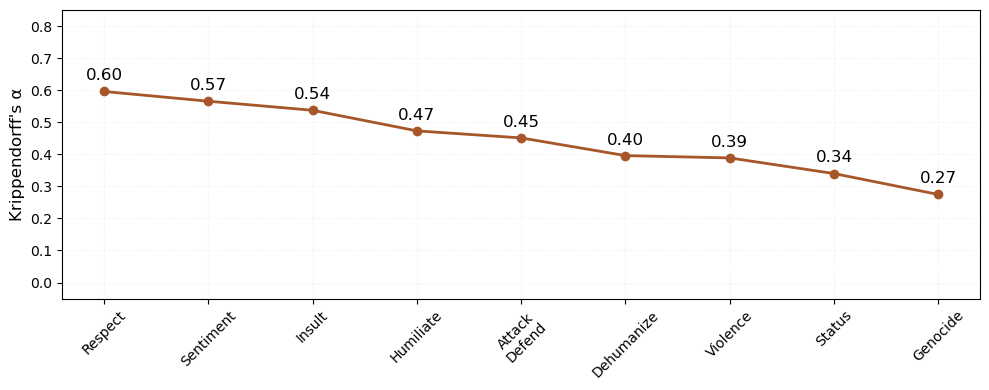

In [8]:
%matplotlib inline
# RUN:
human_kripp_df = compute_human_kripp_baseline(
    human_gold,
    dimensions=DIMENSIONS
)

# SAVE krip output:
human_kripp_df.to_csv(
    OUTPUT_modu_only/
    'human_only_kripp_baseline.csv',
    index=False
)
#plot
fig = plot_human_kripp_baseline(
    human_kripp_df,
    save_path=Figures /
              'human_kripp_baseline.png')

## For eahc LLM 

In [12]:
compute_run_kripp(combined, dimensions=DIMENSIONS).to_csv(
    OUTPUT_modu_5runs / 'kripp_alpha_runs_per_model_noHS.csv',
    index=False
)

# Part 5: Running and saving all metrics

### Running and saving: self-consistency, spread and high variance comments

In [41]:
##### spread and varaince for all models
import json,os
importlib.reload(config)
from config import OUTPUT_modu_5runs

non_modu_model = []
combined = self_consistency_analysis(all_filepaths)
summary  = summarize_consistency_per_model(combined)
flagged  = find_high_variance_comments(combined)

outputs = {
    'sd_spreads_noHS.csv': combined,
    'sd_spreads_per_model_noHS.csv': summary,
    'high_spreads_only.csv': flagged 
}

# for output_csv_name, output in outputs.items():
#     output.to_csv(
#         os.path.join(OUTPUT_modu_5runs, output_csv_name),
#         index=False
#     ) 

deepseek_modu: 250 comments, 256 cells with != 5 runs
gemini_modu: 250 comments, 159 cells with != 5 runs
gpt-5-mini_modu: 250 comments, 168 cells with != 5 runs
claude_modu: 250 comments, 377 cells with != 5 runs


In [58]:
import json
# combined = self_consistency_analysis(all_filepaths)

# summary  = summarize_consistency_per_model(combined)
# flagged  = find_high_variance_comments(combined)

dims8 = [d for d in DIMENSIONS if d != 'sentiment']
miss = pd.concat({d: 5 - combined[f'{d}_n_runs'] for d in dims8}, axis=1) #all dimensions except sentiment with <5 runs
same = miss.nunique(axis=1) == 1                     # how manuy of them have the same number of missing runs in every dimension
print(same.groupby(combined['model']).mean())
print(combined.loc[~same, ['model', 'comment_id']].join(miss[~same]))   # exceptions, e.g. Claude's extra 17 cells
print(5 - combined.groupby('model')['sentiment_n_runs'].apply(lambda s: (s != 5).sum()))   # sentiment check

deepseek_modu: 250 comments, 256 cells with != 5 runs
gemini_modu: 250 comments, 159 cells with != 5 runs
gpt-5-mini_modu: 250 comments, 168 cells with != 5 runs
claude_modu: 250 comments, 377 cells with != 5 runs
model
claude_modu        0.916
deepseek_modu      1.000
gemini_modu        0.996
gpt-5-mini_modu    1.000
dtype: float64
           model  comment_id  respect  insult  humiliate  status  dehumanize  \
492  gemini_modu        3534        2       2          5       2           1   
765  claude_modu       28142        2       2          2       4           2   
775  claude_modu       19725        0       0          0       1           0   
795  claude_modu       31146        0       0          0       1           0   
809  claude_modu        9427        0       0          0       2           0   
814  claude_modu       31475        0       0          0       1           0   
817  claude_modu       10943        0       0          0       3           0   
827  claude_modu       28

In [11]:
summary.head()

,model,sentiment_mean_sd,sentiment_pct_any_disagreement,sentiment_all_zero_pct,sentiment_mean_spread,sentiment_high_spread_pct,respect_mean_sd,respect_pct_any_disagreement,respect_all_zero_pct,respect_mean_spread,...,genocide_mean_sd,genocide_pct_any_disagreement,genocide_all_zero_pct,genocide_mean_spread,genocide_high_spread_pct,attack_defend_mean_sd,attack_defend_pct_any_disagreement,attack_defend_all_zero_pct,attack_defend_mean_spread,attack_defend_high_spread_pct
0,claude_modu,0.123,19.2,0.0,0.260,4.8,0.213,32.1,11.9,0.448,...,0.070,11.9,83.9,0.145,1.8,0.234,35.3,2.8,0.489,12.8
1,deepseek_modu,0.182,30.4,6.0,0.376,5.2,0.234,29.1,7.4,0.513,...,0.038,5.2,92.2,0.082,1.3,0.335,41.7,3.5,0.698,16.5
2,gemini_modu,0.088,17.2,7.6,0.180,0.8,0.189,29.9,9.8,0.400,...,0.006,1.3,96.6,0.013,0.0,0.186,29.5,4.3,0.387,6.8
3,gpt-5-mini_modu,0.116,17.2,6.8,0.236,4.0,0.122,19.3,14.2,0.270,...,0.040,5.2,90.6,0.086,1.7,0.218,31.8,2.1,0.464,10.3


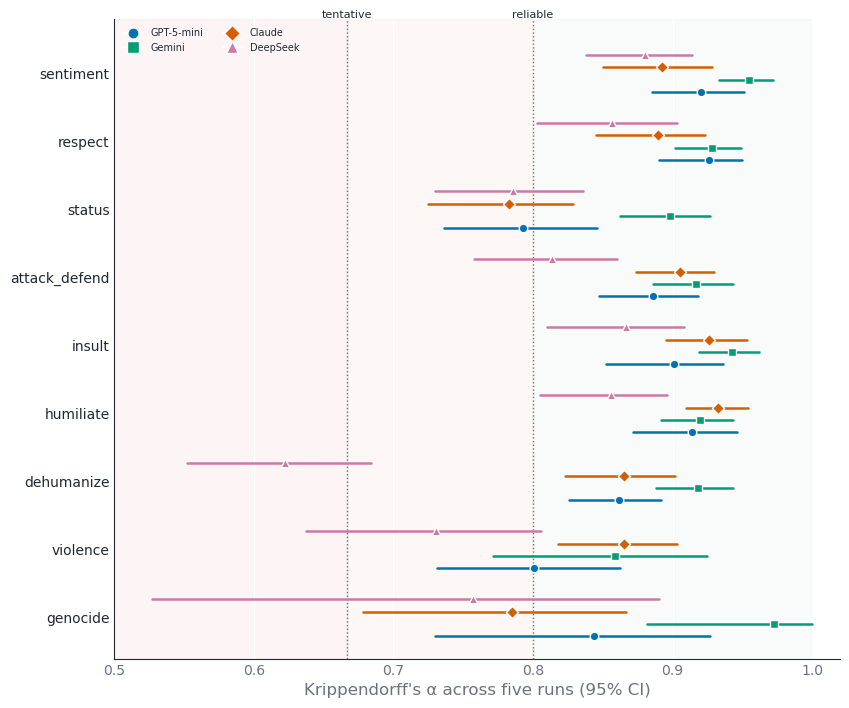

In [256]:
run_run_krip = pd.read_csv(OUTPUT_modu_5runs / 'kripp_alpha_runs_per_model_noHS.csv')
plot_run_alpha(run_run_krip, one_run_final_flat_df, save_path=Figures / 'kripp_alpha_runs_per_model_noHS.png')

## Agreemnt Metrics Human--LLM  and HU--HU Metrics


In [15]:
one_run_all_filepaths = read_filepaths(base_dir=DATA_modu_only) 
one_run_Human_llm_fit_agreement_only, one_run_corr_infit_HU_LLM_agreement = merge_llm_human(human_gold, one_run_all_filepaths, item_fit_stats, anchored_long_df)
one_run_final_flat_df = pd.concat({k: pd.DataFrame(v) for k, v in one_run_Human_llm_fit_agreement_only.items()}, names=['LLM', 'Results'])
one_run_final_flat_df = one_run_final_flat_df.reset_index(level='Results', drop=True).set_index('Dimension', append=True)
# one_run_consistency_path = os.path.join(OUTPUT_modu_only, 'one_run_llm_human_all_metrics_analysis_noHS.csv') 
# one_run_final_flat_df.to_csv(one_run_consistency_path, index=True) 

In [19]:
one_run_final_flat_df.reset_index().head()

,LLM,Dimension,LLM_hu_Bias,LH_bias_CI,LLM_hu_MAE,LH_mae_CI,MAE_hu,MAE_hu_ci,MAE_GAP,MAE_gap_CI,...,n_human_raters,Estimate_joint,SE_joint,Count_joint,Facility_joint,Infit MS_joint,Outfit MS_joint,Infit_anch,Outfit_anch,LLM_hu_abs_bias
0,gpt-5-mini_modu,sentiment,0.2945,"(0.174, 0.41)",0.6531,"(0.574, 0.737)",0.7112,"(0.621, 0.804)",-0.0580,"(-0.131, 0.022)",...,527,-1.747,0.085,1605,0.761,1.576,1.326,1.457,1.314,0.2945
1,gpt-5-mini_modu,respect,0.4217,"(0.264, 0.58)",0.9080,"(0.799, 1.034)",0.7738,"(0.683, 0.869)",0.1342,"(0.018, 0.264)",...,504,-1.672,0.100,1526,0.721,1.530,1.425,1.581,1.440,0.4217
2,gpt-5-mini_modu,insult,0.7175,"(0.538, 0.89)",1.1516,"(1.024, 1.281)",0.8929,"(0.789, 0.999)",0.2587,"(0.121, 0.398)",...,504,-0.657,0.084,1526,0.635,1.654,1.580,1.669,1.658,0.7175
3,gpt-5-mini_modu,humiliate,0.8851,"(0.682, 1.077)",1.3622,"(1.235, 1.493)",0.9661,"(0.857, 1.077)",0.3961,"(0.254, 0.543)",...,504,-0.062,0.071,1525,0.593,1.842,2.002,1.893,1.854,0.8851
4,gpt-5-mini_modu,status,0.6209,"(0.486, 0.746)",0.8617,"(0.761, 0.959)",0.6062,"(0.527, 0.685)",0.2555,"(0.142, 0.371)",...,504,-0.636,0.098,1519,0.704,1.652,3.771,1.457,1.895,0.6209


## Human Baseline

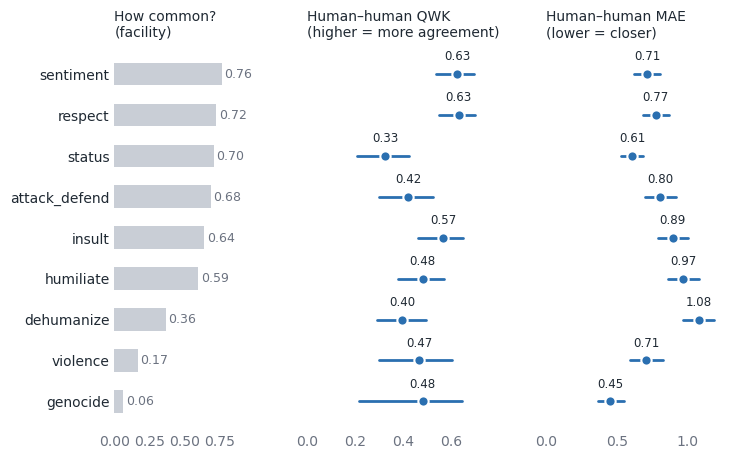

In [21]:
plot_human_baseline(
    one_run_final_flat_df.reset_index(),
    save_path=OUTPUT_modu_only / 'one_run_human_baseline_per_dimension_noHS.png'
)

# Metrics and Fit statistics

### QWK, MAE GAP with Infit and Outfits for each models

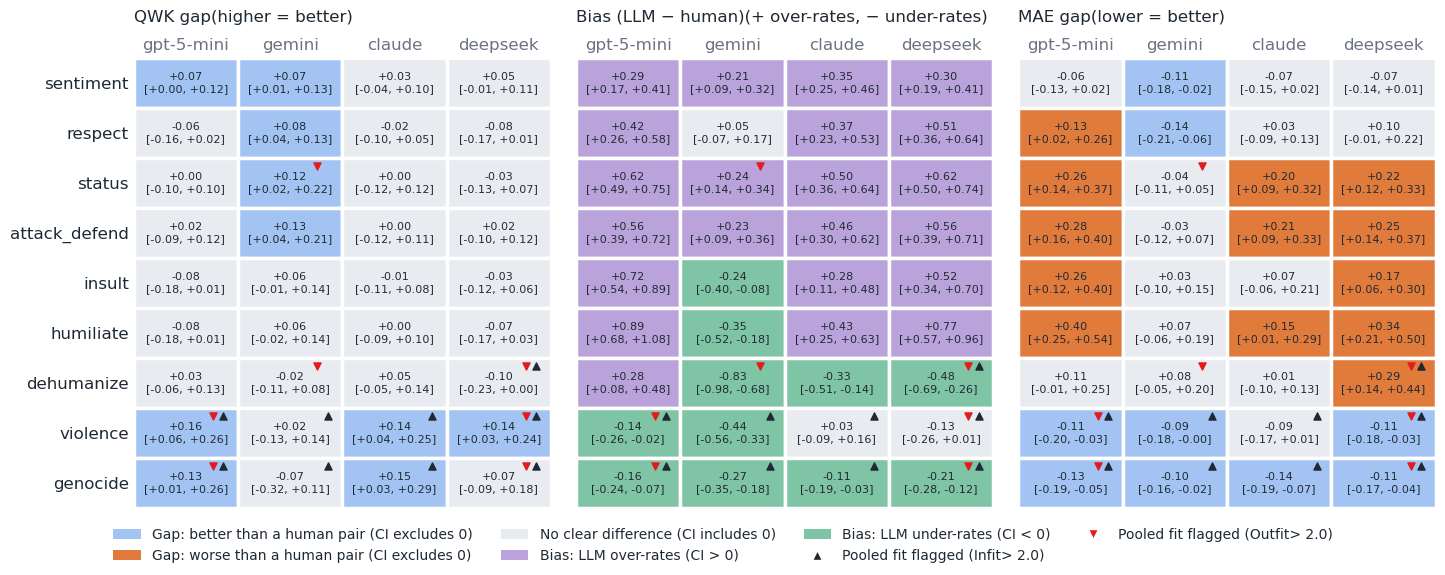

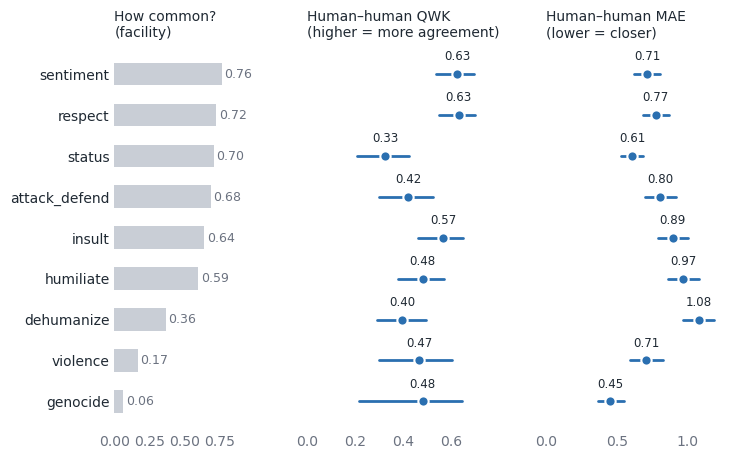

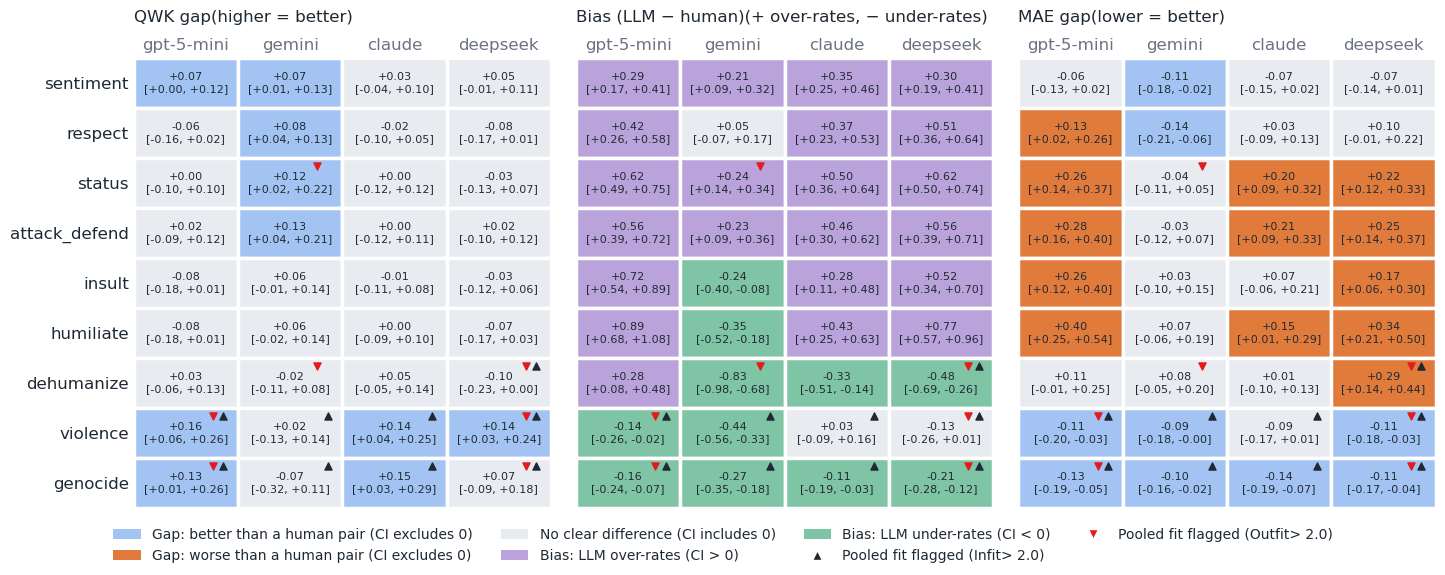

In [22]:
# testing eith a infit and outfit >= 1.5
%matplotlib inline
plot_gap_heatmaps(one_run_final_flat_df.reset_index())

In [133]:
import ast
mae_worse = one_run_final_flat_df.reset_index()['MAE_gap_CI'].map(lambda s: parse_ci(s)[0] > 0)
qwk_worse = one_run_final_flat_df.reset_index()['QWK_gap_CI'].map(lambda s: parse_ci(s)[1] < 0)
flag = (one_run_final_flat_df.reset_index().Infit_anch > 2.0) | (one_run_final_flat_df.reset_index().Outfit_anch > 2.0)
print(pd.crosstab(mae_worse | qwk_worse, flag, margins=True))

col_0  False  True  All
row_0                  
False     13    10   23
True      12     1   13
All       25    11   36


# Inspecting all low facility dimensions across 5 runs

In [23]:
def cross_human_analysis(human_gold, combined, dimensions=['genocide', 'violence']):
    """
    Cross-tabulate human ratings with LLM runs for genocide and violence.
    """
    results = {}
    for dim in dimensions:
        print('@'*100)
        print(dim)
        print('@'*100)
        h = (human_gold.assign(pos=human_gold[dim] > 0)
            .groupby('comment_id').agg(n_pos=('pos','sum'), n_h=('pos','size'), #where n_pos: number of positive rating, n_h:number of human raters, h_max: max rating for genocide
                                        h_max=(dim,'max')))
        h['stratum'] = np.select(
            [h.n_pos == 0, (h.n_pos >= 2) | (h.h_max >= 2)], #consensus: 2 or more rated genocide >=2 or 2 or more human gave rating >=2
            ['no human >0', 'strong +ve rating'], 'single low rating')
        s = combined.merge(h, on='comment_id')
        s['outcome'] = np.select(
            [s[f'{dim}_n_runs'].fillna(0) == 0, s[f'{dim}_n_nonzero'] == 0, s[f'{dim}_n_nonzero'] == s[f'{dim}_n_runs']],
            ['not rated (gated)', 'all runs 0', 'all runs >0'], 'mixed')
        results[dim] = pd.crosstab([s.annotator_id, s.stratum], s.outcome)
        print(results[dim])
    return (results)

from IPython.display import display

results=cross_human_analysis(human_gold, combined, dimensions=['genocide', 'violence'])

@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
genocide
@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
outcome                                           all runs 0  all runs >0  \
annotator_id                   stratum                                      
claude-haiku-4-5-20251001_modu no human >0               116            3   
                               single low rating          49            3   
                               strong +ve rating          21            8   
deepseek-v4-flash_modu         no human >0               127            1   
                               single low rating          54            1   
                               strong +ve rating          33            5   
gemini-3.6-flash_modu          no human >0               131            2   
                               single low rating          56            1   
                   

# Re running fit stats on 4 remaning run model

## First we build the dataset

In [2]:
import os, ast, numpy as np, pandas as pd
AGREE_OUTPUT_DIR_stats_20llmrun = OUTPUT_modu_only/'stats_modu_1run_noHS'/'20_anchor_run'
os.makedirs(AGREE_OUTPUT_DIR_stats_20llmrun, exist_ok=True)
df=pd.read_csv(AGREE_OUTPUT_DIR_stats_nohs/'sd_spreads_noHS.csv')

parse = lambda x: ast.literal_eval(x) if isinstance(x, str) else x
d0 = df[df.comment_id.isin(set(human_gold.comment_id))].copy()      # comments present in the human data
print('LLM comments not in human data:', df.comment_id.nunique() - d0.comment_id.nunique())

def run_frame(d0, r):                                              # runs 1,2,3,4, 5
    out = d0[['comment_id','model']].rename(columns={'model': 'annotator_id'}).copy()
    for dim in DIMENSIONS:
        lst = d0[f'{dim}_5rating'].map(parse)
        ok = (d0[f'{dim}_n_runs'] == 5) & lst.map(lambda l: isinstance(l, list) and len(l) == 5)
        out[dim] = np.where(ok, lst.map(lambda l: l[r - 1] if isinstance(l, list) and len(l) == 5 else np.nan), np.nan)
    return out

run_data = {r: run_frame(d0, r) for r in range(1, 6)}

dataset = {}
for run, data in run_data.items():
    group = data.groupby('annotator_id')
    print(f"run:{run}\n gives the daat head:{data.head(2)}")
    for name, group_df in group:
        print(f"run:{run}, annotator_id:{name}\n gives the group head:{group_df.head(2)}")
        filename = f"{name}_run_{run}.csv"
        filepath = os.path.join(AGREE_OUTPUT_DIR_stats_20llmrun, filename)

        group_df.to_csv(filepath)

LLM comments not in human data: 0
run:1
 gives the daat head:   comment_id   annotator_id  sentiment  respect  insult  humiliate  status  \
0       43341  deepseek_modu        4.0      4.0     4.0        4.0     4.0   
1       27447  deepseek_modu        3.0      1.0     0.0        0.0     2.0   

   dehumanize  violence  genocide  attack_defend  
0         0.0       0.0       0.0            4.0  
1         0.0       0.0       0.0            0.0  
run:1, annotator_id:claude_modu
 gives the group head:     comment_id annotator_id  sentiment  respect  insult  humiliate  status  \
750       43341  claude_modu        4.0      4.0     4.0        4.0     4.0   
751       27447  claude_modu        3.0      1.0     0.0        0.0     2.0   

     dehumanize  violence  genocide  attack_defend  
750         1.0       0.0       0.0            4.0  
751         0.0       0.0       0.0            1.0  
run:1, annotator_id:deepseek_modu
 gives the group head:   comment_id   annotator_id  sentiment  

In [36]:
import RaschPy_aies 
from RaschPy_aies import RaschPy as rp
import re, tempfile
from pathlib import Path
FILE_RE = re.compile(r"^(?P<judge>.+)_run_(?P<run>\d+)\.csv$")
base_dir = out_dir = AGREE_OUTPUT_DIR_stats_20llmrun
import time

def calibrate(filepath, label):
    """Helper to load and calibrate MFRM model."""
    print(f"  Calibrating {label}...")
    data, _ = rp.loadup_mfrm_single(filepath)
    model   = rp.MFRM(data)
    model.calibrate_global()
    return model
    
def data_differentiate_raters(df, annotator_label=None):
    rater_params = df.copy()
    if annotator_label == 'gold':
        pass
    else:
        rater_params['annotator_id'] = annotator_label
    return rater_params
    
def build_human_plus_llm(human_df, llm_df, judge, dims=DIMENSIONS):
    cols = ['annotator_id', 'comment_id'] + list(dims)          
    human = data_differentiate_raters(human_df[cols], annotator_label='gold')   # ids unchanged
    llm   = data_differentiate_raters(llm_df[cols],   annotator_label=judge)    # one rater id per judge
    return pd.concat([human, llm], ignore_index=True)


def extract_item_fit(model, judge=None):
    model.item_stats_df_global()
    stats = model.item_stats_global.reset_index()
    out = stats.rename(columns={'Infit MS': 'Infit_anch', 'Outfit MS': 'Outfit_anch'})
    out = out.rename(columns={out.columns[0]: 'Dimension'}) if 'Dimension' not in out else out
    return out


def fit_fn(llm_df, human_df):
    judge = llm_df['annotator_id'].iloc[0]
    path = base_dir / f'mfrm_human_{judge}.csv'
    build_human_plus_llm(human_df, llm_df, judge).to_csv(path, index=False)
    # print(pd.read_csv(path).columns[:3].tolist())
    return extract_item_fit(calibrate(str(path), judge))

def run_batch(run_dir, human_df, fit_fn, out_dir, overwrite = False, verbose= True):
    """Fit every <judge>_run_<r>.csv in run_dir; one result CSV per file (so a crash loses nothing)."""
    run_dir, out_dir = Path(run_dir), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    files = sorted(p for p in run_dir.glob("*_run_*.csv") if FILE_RE.match(p.name))
    if not files:
        raise FileNotFoundError(f"no *_run_*.csv files in {run_dir}")
    parts = []
    for i, p in enumerate(files, 1):
        m = FILE_RE.match(p.name)
        judge, run = m["judge"], int(m["run"])
        res_path = out_dir / f"fit_{judge}_run_{run}.csv"
        if res_path.exists() and not overwrite:
            res = pd.read_csv(res_path)
            if verbose: print(f"[{i}/{len(files)}] {p.name}: loaded cached result")
        else:
            if verbose: print(f"[{i}/{len(files)}] {p.name}: fitting ...", flush=True)
            res = fit_fn(pd.read_csv(p), human_df).assign(LLM=judge, run=run)
            res.to_csv(res_path, index=False)
        parts.append(res)
        print(f'Output saved to {res_path}')
    all_runs = pd.concat(parts, ignore_index=True)
    all_runs.to_csv(out_dir / "all_runs_fit.csv", index=False)
    return all_runs

def summarize(all_runs, infit="Infit_anch", outfit="Outfit_anch", cut=2.0):
    """Per judge x dimension: spread of Infit/Outfit across runs and how many runs exceed `cut`."""
    d = all_runs.copy()
    d["flag"] = (d[infit] > cut) | (d[outfit] > cut)
    return (d.groupby(["LLM", "Dimension"])
              .agg(n_runs=("run", "nunique"),
                   infit_mean=(infit, "mean"), infit_min=(infit, "min"), infit_max=(infit, "max"),
                   infit_sd=(infit, "std"),
                   outfit_mean=(outfit, "mean"), outfit_min=(outfit, "min"), outfit_max=(outfit, "max"),
                   runs_flagged=("flag", "sum"))
              .reset_index())


def control_table(all_runs, original, run=1,
                  infit="Infit_anch", outfit="Outfit_anch", cut=2.0) -> pd.DataFrame:
    """Run `run` on the common comment set vs your original fit: does restricting the comments change flags?"""
    a = all_runs[all_runs.run == run][["LLM", "Dimension", infit, outfit]]
    o = original[["LLM", "Dimension", infit, outfit]]
    m = a.merge(o, on=["LLM", "Dimension"], suffixes=("_common", "_orig"))
    m["infit_diff"] = m[f"{infit}_common"] - m[f"{infit}_orig"]
    m["flag_common"] = (m[f"{infit}_common"] > cut) | (m[f"{outfit}_common"] > cut)
    m["flag_orig"] = (m[f"{infit}_orig"] > cut) | (m[f"{outfit}_orig"] > cut)
    m["flag_changed"] = m.flag_common != m.flag_orig
    return m

In [ ]:
all_runs = run_batch(base_dir, human_gold, fit_fn, out_dir=base_dir / 'results', overwrite=False, verbose=True)  # all 5 runs for all judges


In [6]:
summ = summarize(all_runs)                                    # per judge x dimension: mean, min, max, SD, runs flagged


In [7]:
summ

,LLM,Dimension,n_runs,infit_mean,infit_min,infit_max,infit_sd,outfit_mean,outfit_min,outfit_max,runs_flagged
0,claude_modu,attack_defend,5,1.2790,1.250,1.308,0.021378,1.3522,1.312,1.409,0
1,claude_modu,dehumanize,5,1.9062,1.814,2.023,0.086178,1.9900,1.765,2.291,2
2,claude_modu,genocide,5,2.1780,2.078,2.241,0.061640,1.8120,1.755,1.855,5
3,claude_modu,humiliate,5,1.6392,1.586,1.681,0.039544,1.6416,1.526,1.762,0
4,claude_modu,insult,5,1.3992,1.351,1.437,0.038655,1.3576,1.298,1.411,0
5,claude_modu,respect,5,1.5026,1.478,1.532,0.020144,1.3664,1.318,1.422,0
6,claude_modu,sentiment,5,1.2260,1.192,1.280,0.034706,1.1168,1.061,1.236,0
7,claude_modu,status,5,1.3848,1.349,1.449,0.038797,1.9554,1.841,2.175,1
8,claude_modu,violence,5,2.0454,2.032,2.061,0.010644,1.7866,1.774,1.810,5
9,deepseek_modu,attack_defend,5,1.3204,1.260,1.389,0.048221,1.3444,1.273,1.484,0


In [19]:
claude_only = df[df['annotator_id']=='claude-haiku-4-5-20251001_modu']
claude_only.head()

,comment_id,annotator_id,sentiment_5rating,sentiment_n_runs,sentiment_sd,sentiment_spread,sentiment_n_nonzero,sentiment_entropy,respect_5rating,respect_n_runs,...,genocide_spread,genocide_n_nonzero,genocide_entropy,attack_defend_5rating,attack_defend_n_runs,attack_defend_sd,attack_defend_spread,attack_defend_n_nonzero,attack_defend_entropy,model
750,43341,claude-haiku-4-5-20251001_modu,"[4, 4, 4, 4, 4]",5,0.000,0,5,0.000,"[4, 4, 4, 4, 4]",5,...,0.0,0.0,0.0,"[4, 4, 4, 4, 4]",5,0.0,0.0,5.0,0.0,claude_modu
751,27447,claude-haiku-4-5-20251001_modu,"[3, 3, 3, 4, 4]",5,0.548,1,5,0.971,"[1, 1, 2, 2, 2]",5,...,0.0,0.0,0.0,"[1, 1, 1, 1, 1]",5,0.0,0.0,5.0,0.0,claude_modu
752,31223,claude-haiku-4-5-20251001_modu,"[1, 1, 1, 1, 1]",5,0.000,0,5,0.000,"[1, 2, 2, 2, 2]",5,...,0.0,0.0,0.0,"[1, 1, 1, 1, 1]",5,0.0,0.0,5.0,0.0,claude_modu
753,43580,claude-haiku-4-5-20251001_modu,"[4, 4, 4, 4, 4]",5,0.000,0,5,0.000,"[3, 4, 4, 4, 4]",5,...,0.0,0.0,0.0,"[4, 4, 4, 4, 4]",5,0.0,0.0,5.0,0.0,claude_modu
754,48916,claude-haiku-4-5-20251001_modu,"[4, 4, 4, 4, 4]",5,0.000,0,5,0.000,"[4, 4, 4, 4, 4]",5,...,0.0,0.0,0.0,"[4, 4, 4, 4, 4]",5,0.0,0.0,5.0,0.0,claude_modu


In [35]:
# r1: run-1 file (judge, comment_id, dims); df: consolidated file with *_5rating / vote counts
m = pd.merge(r1, claude_only, on=["comment_id", 'annotator_id'], how="inner")

rows = []
for d in DIMENSIONS:
    L = m[f"{d}_5rating"].map(parse)
    ok = m[d].notna() & L.map(lambda l: isinstance(l, (list, tuple)) and len(l) == 5)
    mixed = ok & L.map(lambda l: isinstance(l, (list, tuple)) and len(set(l)) > 1)
    v, l = m.loc[mixed, d], L[mixed]
    rows.append({
        "dim": d, "n_mixed": int(mixed.sum()),
        "r1==min": (v == l.map(min)).mean(),
        "r1==max": (v == l.map(max)).mean(),
        "expected_if_random": l.map(lambda x: x.count(min(x)) / 5).mean(),  # chance that a random draw equals the min
    })
print(pd.DataFrame(rows).round(3))

             dim  n_mixed  r1==min  r1==max  expected_if_random
0      sentiment       48    0.438    0.500               0.463
1        respect       68    0.324    0.632               0.412
2         insult       62    0.452    0.452               0.435
3      humiliate       65    0.446    0.462               0.449
4         status       88    0.307    0.580               0.373
5     dehumanize       81    0.358    0.444               0.417
6       violence       58    0.483    0.431               0.472
7       genocide       25    0.480    0.480               0.456
8  attack_defend       74    0.527    0.419               0.451


### Computing standard deviation and variability across models and dimensions

In [53]:
import numpy as np, pandas as pd

def variability_table(per_comment_var_df, alpha_df, min_runs=5, model_col="model"):
    rows = []
    for model, g in per_comment_var_df.groupby(model_col):
        for d in DIMENSIONS:
            x = g[g[f"{d}_n_runs"] >= min_runs]
            nz = x[x[f"{d}_n_nonzero"] > 0]            # at least one run above 0
            rows.append({
                "Model": model, 
                "Dimension": d,
                "n_comments": len(x),
                "all_zero_pct": 100 * (1 - len(nz) / len(x)) if len(x) else np.nan,
                "pct_any_disagreement_all": 100 * (x[f"{d}_spread"] > 0).mean() if len(x) else np.nan,
                "n_nonzero_comments": len(nz),
                "pct_any_disagreement_nonzero": 100 * (nz[f"{d}_spread"] > 0).mean() if len(nz) else np.nan,
                "mean_sd_nonzero": nz[f"{d}_sd"].mean() if len(nz) else np.nan,
                "mean_spread_nonzero": nz[f"{d}_spread"].mean() if len(nz) else np.nan,
            })
    out = pd.DataFrame(rows)
    if alpha_df is not None:
        out = out.merge(alpha_df[["Model", "Dimension", "Kripp_alpha_runs"]],
                        on=["Model", "Dimension"], how="left")
    return out

def per_dimension_summary(cell_table):
    """Mean of the four judges' cell values, with the range across judges."""
    cols = ["pct_any_disagreement_nonzero", "mean_sd_nonzero", "mean_spread_nonzero"]
    g = cell_table.groupby("Dimension")[cols].agg(["mean", "min", "max"]).round(3)
    return g.loc[DIMENSIONS]

cells = variability_table(flagged, alpha_df=run_run_krip)
per_dimension_summary(cells) 

pct_any_disagreement_nonzero                 mean_sd_nonzero  \
                                      mean     min     max            mean   
Dimension                                                                    
sentiment                           22.153  18.455  32.340           0.134   
respect                             31.286  22.449  37.989           0.215   
insult                              30.821  20.635  37.805           0.252   
humiliate                           37.831  21.164  53.205           0.274   
status                              37.388  24.454  47.059           0.255   
dehumanize                          62.037  40.650  84.828           0.568   
violence                            65.614  55.238  77.333           0.455   
genocide                            59.041  37.500  73.529           0.389   
attack_defend                       36.360  30.455  44.762           0.255   

                            mean_spread_nonzero                
                 min    max                mean    min    max  
Dimension                                                      
sentiment      0.095  0.194               0.277  0.195  0.400  
respect        0.143  0.260               0.467  0.316  0.577  
insult         0.199  0.305               0.544  0.423  0.663  
humiliate      0.171  0.344               0.596  0.365  0.744  
status         0.136  0.359               0.551  0.288  0.786  
dehumanize     0.243  0.993               1.242  0.520  2.193  
violence       0.330  0.614               0.972  0.714  1.320  
genocide       0.180  0.512               0.828  0.375  1.118  
attack_defend  0.189  0.360               0.539  0.395  0.757

In [45]:
per_dimensions_variability_analysis = per_dimension_summary(cells) 
cells.round(3).to_csv(OUTPUT_modu_5runs/"all_variability_cells.csv", index=False)   # appendix table
per_dimensions_variability_analysis.round(3).to_csv(OUTPUT_modu_5runs/"per_dimensions_variability_analysis.csv", index=False)   # appendix table

In [54]:
cells

,Model,Dimension,n_comments,all_zero_pct,pct_any_disagreement_all,n_nonzero_comments,pct_any_disagreement_nonzero,mean_sd_nonzero,mean_spread_nonzero,Kripp_alpha_runs
0,claude_modu,sentiment,250,0.000000,19.200000,250,19.200000,0.123060,0.260000,0.8922
1,claude_modu,respect,205,12.682927,33.170732,179,37.988827,0.250682,0.536313,0.8898
2,claude_modu,insult,205,20.000000,30.243902,164,37.804878,0.250445,0.536585,0.9259
3,claude_modu,humiliate,205,20.487805,31.707317,163,39.877301,0.248859,0.546012,0.9329
4,claude_modu,status,188,0.531915,46.808511,187,47.058824,0.358840,0.786096,0.7829
5,claude_modu,dehumanize,205,34.634146,39.512195,134,60.447761,0.510500,1.111940,0.8651
6,claude_modu,violence,205,48.780488,28.292683,105,55.238095,0.330295,0.714286,0.8651
7,claude_modu,genocide,205,83.414634,12.195122,34,73.529412,0.434794,0.911765,0.7848
8,claude_modu,attack_defend,205,2.926829,36.097561,199,37.185930,0.245623,0.522613,0.9056
9,deepseek_modu,sentiment,250,6.000000,30.400000,235,32.340426,0.193579,0.400000,0.8805
